# Program 1 — Supervised Learning: Predicting Malignant vs Benign Tumours

**Owner of this notebook:** Atyadik Kumar Anand (241010251)
**Input:** `data/train.csv`, `data/test.csv` (created by `01_data_and_eda.ipynb`)

### Goal
Train a classifier that predicts `Malignant (1)` or `Benign (0)` from the 30 nucleus measurements.

### Which metric matters most?
| Error | Meaning | Cost |
|---|---|---|
| **False Negative** | cancer predicted as benign | **Very high**: treatment is delayed |
| False Positive | benign predicted as cancer | Lower: one extra biopsy |

So **recall on the malignant class** (sensitivity) is the most important metric, while precision must stay
reasonable. We use **F1** for model selection and then **tune the decision threshold** to push recall higher.

### Workflow
1. Compare 7 algorithms using 5-fold stratified cross-validation
2. Tune the hyperparameters of the 3 best with `GridSearchCV`
3. Evaluate on the held-out test set (used **once**)
4. Tune the decision threshold for higher recall
5. Interpret the model (coefficients, feature importance) and check bias vs variance (learning curve)

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (StratifiedKFold, cross_validate, GridSearchCV,
                                     cross_val_predict, learning_curve)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             RocCurveDisplay, PrecisionRecallDisplay, precision_recall_curve)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
FIG_DIR, RES_DIR, MODEL_DIR = Path("figures"), Path("results"), Path("models")
for d in (FIG_DIR, RES_DIR, MODEL_DIR):
    d.mkdir(exist_ok=True)

In [2]:
train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")
FEATURES = [c for c in train.columns if c not in ("target", "diagnosis")]

X_train, y_train = train[FEATURES], train["target"]
X_test, y_test = test[FEATURES], test["target"]
print(f"Train: {X_train.shape}, malignant = {y_train.mean():.1%}")
print(f"Test : {X_test.shape}, malignant = {y_test.mean():.1%}")

Train: (455, 30), malignant = 37.4%
Test : (114, 30), malignant = 36.8%


## 1. Candidate models
Every model is wrapped in a **`Pipeline(StandardScaler → model)`**. Inside cross-validation the scaler is
fitted **only on the training folds**, so no information from the validation fold leaks into preprocessing.

| Model | Type | Why include it |
|---|---|---|
| Logistic Regression | linear, probabilistic | strong interpretable baseline |
| K-Nearest Neighbours | instance-based | distance-based; shows why scaling matters |
| SVM (RBF kernel) | maximum-margin, non-linear | works well on high-dimensional data |
| Decision Tree | rule-based | readable, but prone to overfitting |
| Random Forest | bagging ensemble | reduces the variance of a single tree |
| Gradient Boosting | boosting ensemble | reduces bias by fitting trees one after another |
| Gaussian Naive Bayes | probabilistic | very fast; assumes features are independent |

In [3]:
def make_pipe(model):
    return Pipeline([("scaler", StandardScaler()), ("model", model)])

models = {
    "Logistic Regression": make_pipe(LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
    "KNN": make_pipe(KNeighborsClassifier()),
    "SVM (RBF)": make_pipe(SVC(probability=True, random_state=RANDOM_STATE)),
    "Decision Tree": make_pipe(DecisionTreeClassifier(random_state=RANDOM_STATE)),
    "Random Forest": make_pipe(RandomForestClassifier(random_state=RANDOM_STATE)),
    "Gradient Boosting": make_pipe(GradientBoostingClassifier(random_state=RANDOM_STATE)),
    "Naive Bayes": make_pipe(GaussianNB()),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = ["accuracy", "precision", "recall", "f1", "roc_auc"]

## 2. Baseline comparison — 5-fold stratified cross-validation (training set only)

In [4]:
rows = []
for name, pipe in models.items():
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=SCORING)
    rows.append({"model": name,
                 **{m: s[f"test_{m}"].mean() for m in SCORING},
                 "f1_std": s["test_f1"].std()})
baseline = pd.DataFrame(rows).set_index("model").sort_values("f1", ascending=False)
baseline.to_csv(RES_DIR / "supervised_baseline_cv.csv")
baseline.round(4)

,accuracy,precision,recall,f1,roc_auc,f1_std
model,,,,,,
Logistic Regression,0.9736,0.9771,0.9529,0.9640,0.9958,0.0207
SVM (RBF),0.9714,0.9769,0.9471,0.9610,0.9949,0.0082
Gradient Boosting,0.9670,0.9646,0.9471,0.9553,0.9908,0.0196
Random Forest,0.9648,0.9641,0.9412,0.9519,0.9889,0.0207
KNN,0.9648,0.9875,0.9176,0.9510,0.9871,0.0263
Naive Bayes,0.9385,0.9247,0.9118,0.9170,0.9870,0.0342
Decision Tree,0.9231,0.8996,0.8941,0.8962,0.9172,0.0447


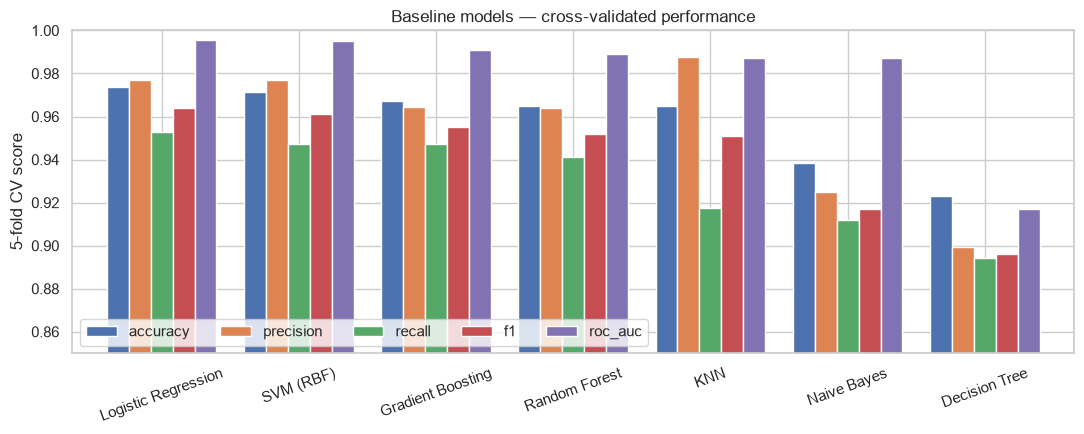

In [5]:
fig, ax = plt.subplots(figsize=(11, 4.5))
baseline[["accuracy", "precision", "recall", "f1", "roc_auc"]].plot.bar(ax=ax, width=0.8)
ax.set_ylim(0.85, 1.0); ax.set_ylabel("5-fold CV score"); ax.set_xlabel("")
ax.set_title("Baseline models — cross-validated performance")
ax.legend(loc="lower left", ncol=5); ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.savefig(FIG_DIR / "02_baseline_comparison.png", dpi=150); plt.show()

**Reading the baseline:**
* The **linear model (Logistic Regression) and SVM** are at the top. The classes are almost linearly
  separable once the features are scaled.
* The **single Decision Tree** is the weakest and its score varies most across folds. This is the classic
  high-variance behaviour that Random Forest fixes by averaging many trees.
* **Naive Bayes** trails because its independence assumption is broken by the strongly correlated features (see EDA).

## 3. Hyperparameter tuning — `GridSearchCV` (scoring = F1, 5-fold stratified CV)
We tune three models from different families: a linear model, a kernel model, and an ensemble.

In [6]:
grids = {
    "Logistic Regression": (models["Logistic Regression"], {
        "model__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100],
        "model__penalty": ["l2"],
        "model__class_weight": [None, "balanced"],
    }),
    "SVM (RBF)": (models["SVM (RBF)"], {
        "model__C": [0.1, 0.3, 1, 3, 10, 30, 100],
        "model__gamma": ["scale", 0.001, 0.003, 0.01, 0.03, 0.1],
        "model__class_weight": [None, "balanced"],
    }),
    "Random Forest": (models["Random Forest"], {
        "model__n_estimators": [200, 500],
        "model__max_depth": [None, 5, 10],
        "model__min_samples_leaf": [1, 2, 4],
        "model__max_features": ["sqrt", "log2"],
        "model__class_weight": [None, "balanced"],
    }),
}

tuned, tuning_rows = {}, []
for name, (pipe, grid) in grids.items():
    gs = GridSearchCV(pipe, grid, scoring="f1", cv=cv, n_jobs=-1)
    gs.fit(X_train, y_train)
    tuned[name] = gs.best_estimator_
    tuning_rows.append({"model": name,
                        "baseline CV F1": baseline.loc[name, "f1"],
                        "tuned CV F1": gs.best_score_,
                        "best params": {k.replace("model__", ""): v for k, v in gs.best_params_.items()}})
tuning = pd.DataFrame(tuning_rows).set_index("model").sort_values("tuned CV F1", ascending=False)
tuning.to_csv(RES_DIR / "supervised_tuning.csv")
pd.set_option("display.max_colwidth", 120)
tuning

,baseline CV F1,tuned CV F1,best params
model,,,
SVM (RBF),0.960987,0.976009,"{'C': 3, 'class_weight': 'balanced', 'gamma': 0.01}"
Logistic Regression,0.964048,0.967240,"{'C': 0.3, 'class_weight': 'balanced', 'penalty': 'l2'}"
Random Forest,0.951945,0.955720,"{'class_weight': None, 'max_depth': 10, 'max_features': 'log2', 'min_samples_leaf': 1, 'n_estimators': 200}"


**Final model choice:** the model with the **highest tuned cross-validated F1**. It is chosen *before*
looking at the test set, so the test score is an honest estimate of performance on new patients.

In [7]:
FINAL_NAME = tuning.index[0]
final_model = tuned[FINAL_NAME]
print("Selected final model:", FINAL_NAME)
print(final_model)

Selected final model: SVM (RBF)
Pipeline(steps=[('scaler', StandardScaler()),
                ('model',
                 SVC(C=3, class_weight='balanced', gamma=0.01, probability=True,
                     random_state=42))])


## 4. Evaluation on the held-out test set (114 patients never seen during training or tuning)

In [8]:
def evaluate(model, X, y, threshold=0.5):
    proba = model.predict_proba(X)[:, 1]
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return {"accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred),
            "recall (sensitivity)": recall_score(y, pred), "specificity": tn / (tn + fp),
            "f1": f1_score(y, pred), "roc_auc": roc_auc_score(y, proba),
            "false negatives": fn, "false positives": fp}

test_results = pd.DataFrame({name: evaluate(m, X_test, y_test) for name, m in tuned.items()}).T
test_results = test_results.loc[tuning.index]
test_results.to_csv(RES_DIR / "supervised_test_metrics.csv")
test_results.round(4)

,accuracy,precision,recall (sensitivity),specificity,f1,roc_auc,false negatives,false positives
SVM (RBF),0.9825,1.0000,0.9524,1.0000,0.9756,0.9974,2.0,0.0
Logistic Regression,0.9825,0.9762,0.9762,0.9861,0.9762,0.9974,1.0,1.0
Random Forest,0.9561,1.0000,0.8810,1.0000,0.9367,0.9942,5.0,0.0


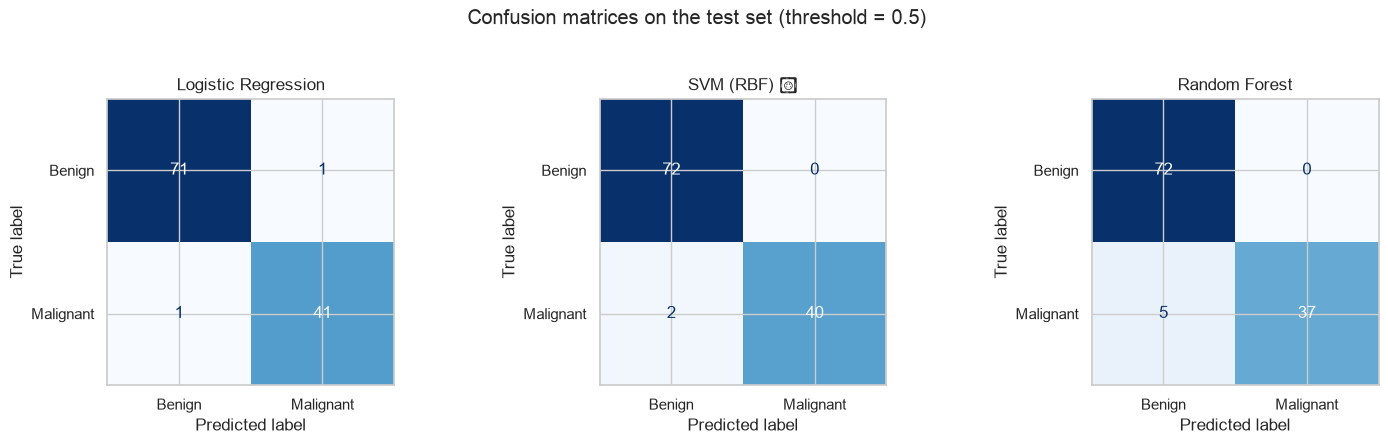

In [9]:
def predict_at(model, X, threshold=0.5):
    """Predict malignant when P(malignant) >= threshold (used everywhere, so all tables agree)."""
    return (model.predict_proba(X)[:, 1] >= threshold).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, (name, m) in zip(axes, tuned.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, predict_at(m, X_test)),
                           display_labels=["Benign", "Malignant"]).plot(cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name + (" ★" if name == FINAL_NAME else ""))
plt.suptitle("Confusion matrices on the test set (threshold = 0.5)", y=1.03)
plt.tight_layout(); plt.savefig(FIG_DIR / "02_confusion_matrices.png", dpi=150, bbox_inches="tight"); plt.show()

In [10]:
print(f"Classification report — {FINAL_NAME} (test set, threshold 0.5)\n")
print(classification_report(y_test, predict_at(final_model, X_test), target_names=["Benign", "Malignant"], digits=4))

Classification report — SVM (RBF) (test set, threshold 0.5)

              precision    recall  f1-score   support

      Benign     0.9730    1.0000    0.9863        72
   Malignant     1.0000    0.9524    0.9756        42

    accuracy                         0.9825       114
   macro avg     0.9865    0.9762    0.9810       114
weighted avg     0.9829    0.9825    0.9824       114



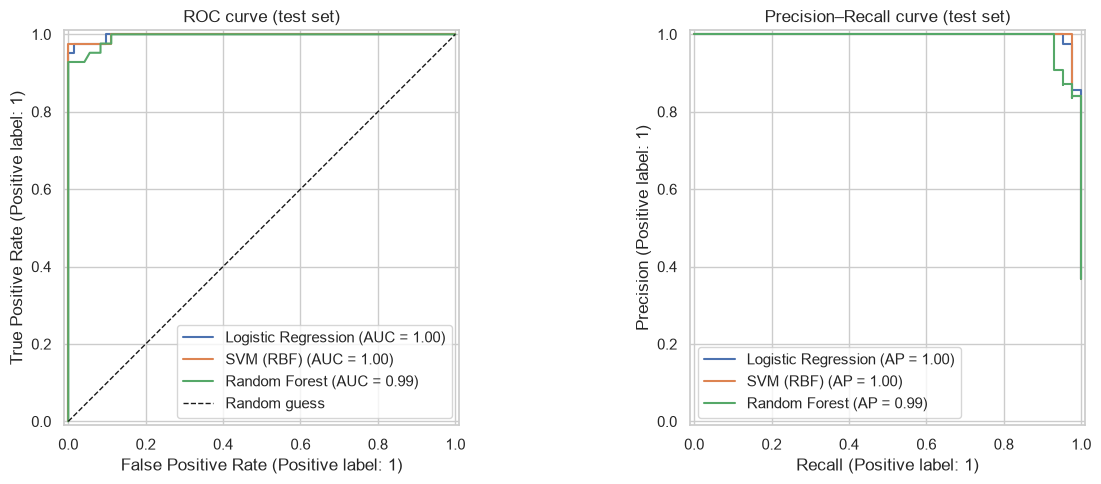

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, m in tuned.items():
    RocCurveDisplay.from_estimator(m, X_test, y_test, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_estimator(m, X_test, y_test, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Random guess"); axes[0].legend(loc="lower right")
axes[0].set_title("ROC curve (test set)"); axes[1].set_title("Precision–Recall curve (test set)")
axes[1].legend(loc="lower left")
plt.tight_layout(); plt.savefig(FIG_DIR / "02_roc_pr_curves.png", dpi=150); plt.show()

## 5. Decision-threshold tuning: catching more cancers
A classifier outputs a **probability**. By default we predict malignant when *p ≥ 0.5*. Lowering the threshold
gives **higher recall** (fewer missed cancers) at the cost of lower precision (more false alarms).

**How we choose it without cheating:** we get *out-of-fold* probabilities on the **training set** with
`cross_val_predict` and pick the **highest threshold that still gives at least 98% recall**. Only then do we
apply that threshold to the test set.

Chosen threshold (from training CV): 0.344


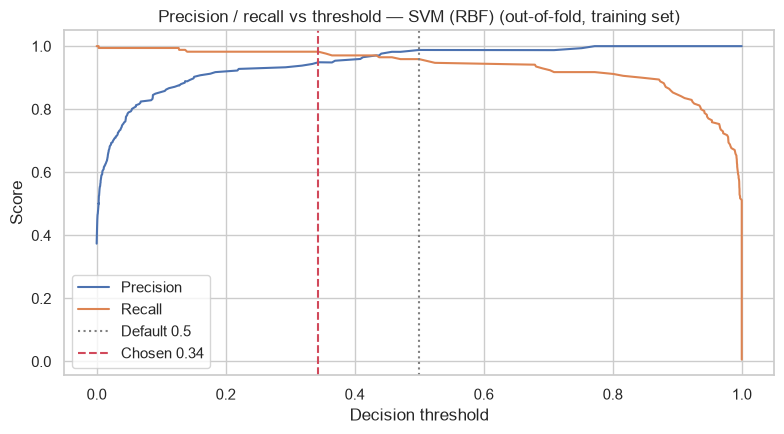

In [12]:
TARGET_RECALL = 0.98
oof_proba = cross_val_predict(final_model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof_proba)
ok = np.where(rec[:-1] >= TARGET_RECALL)[0]
best_threshold = float(thr[ok].max())
print(f"Chosen threshold (from training CV): {best_threshold:.3f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(thr, prec[:-1], label="Precision")
ax.plot(thr, rec[:-1], label="Recall")
ax.axvline(0.5, color="grey", ls=":", label="Default 0.5")
ax.axvline(best_threshold, color="#D1495B", ls="--", label=f"Chosen {best_threshold:.2f}")
ax.set_xlabel("Decision threshold"); ax.set_ylabel("Score")
ax.set_title(f"Precision / recall vs threshold — {FINAL_NAME} (out-of-fold, training set)")
ax.legend(); plt.tight_layout(); plt.savefig(FIG_DIR / "02_threshold_tuning.png", dpi=150); plt.show()

In [13]:
thr_compare = pd.DataFrame({
    "default (0.50)": evaluate(final_model, X_test, y_test, 0.5),
    f"tuned ({best_threshold:.2f})": evaluate(final_model, X_test, y_test, best_threshold),
}).T
thr_compare.to_csv(RES_DIR / "supervised_threshold_comparison.csv")
thr_compare.round(4)

,accuracy,precision,recall (sensitivity),specificity,f1,roc_auc,false negatives,false positives
default (0.50),0.9825,1.0000,0.9524,1.0000,0.9756,0.9974,2.0,0.0
tuned (0.34),0.9825,0.9762,0.9762,0.9861,0.9762,0.9974,1.0,1.0


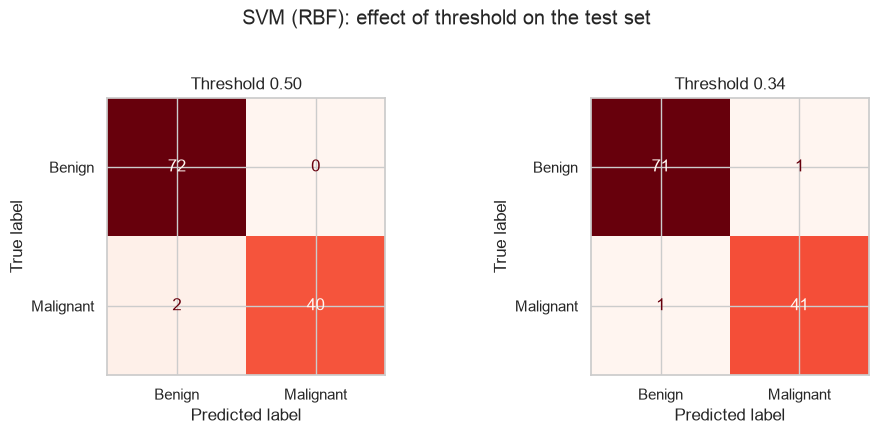

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, (label, t) in zip(axes, [("Threshold 0.50", 0.5), (f"Threshold {best_threshold:.2f}", best_threshold)]):
    pred = predict_at(final_model, X_test, t)
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Benign", "Malignant"]).plot(
        cmap="Reds", colorbar=False, ax=ax)
    ax.set_title(label)
plt.suptitle(f"{FINAL_NAME}: effect of threshold on the test set", y=1.03)
plt.tight_layout(); plt.savefig(FIG_DIR / "02_threshold_confusion.png", dpi=150, bbox_inches="tight"); plt.show()

## 6. Model interpretation: which features drive the prediction?
* **Permutation importance** (model-agnostic): shuffle one feature on the test set and measure how much
  ROC-AUC drops. A bigger drop means the model relies on that feature more.
* **Logistic Regression coefficients**: on standardised features, the sign shows the direction
  (positive → pushes towards malignant) and the size shows strength.
* **Random Forest impurity importance**: how much each feature reduces Gini impurity across all trees.

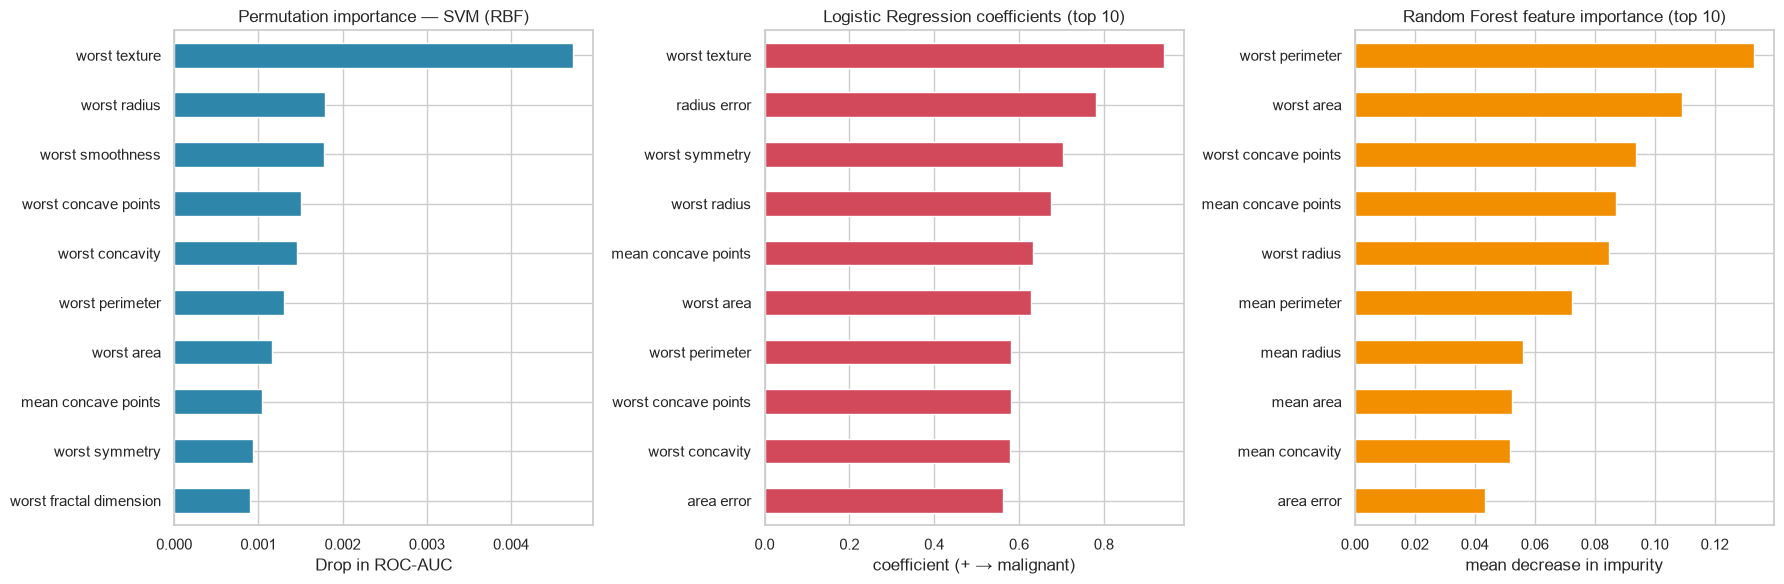

Top 5 by permutation importance: worst texture, worst radius, worst smoothness, worst concave points, worst concavity
Top 5 by |LR coefficient|      : worst texture, radius error, worst symmetry, worst radius, mean concave points
Top 5 by RF importance         : worst perimeter, worst area, worst concave points, mean concave points, worst radius


In [15]:
perm = permutation_importance(final_model, X_test, y_test, scoring="roc_auc",
                              n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values(ascending=False)

lr_coef = pd.Series(tuned["Logistic Regression"].named_steps["model"].coef_[0], index=FEATURES)
rf_imp = pd.Series(tuned["Random Forest"].named_steps["model"].feature_importances_, index=FEATURES)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
perm_imp.head(10)[::-1].plot.barh(ax=axes[0], color="#2E86AB")
axes[0].set_title(f"Permutation importance — {FINAL_NAME}"); axes[0].set_xlabel("Drop in ROC-AUC")
top_lr = lr_coef.reindex(lr_coef.abs().sort_values(ascending=False).index).head(10)[::-1]
top_lr.plot.barh(ax=axes[1], color=["#D1495B" if v > 0 else "#4C9F70" for v in top_lr])
axes[1].set_title("Logistic Regression coefficients (top 10)"); axes[1].set_xlabel("coefficient (+ → malignant)")
rf_imp.sort_values(ascending=False).head(10)[::-1].plot.barh(ax=axes[2], color="#F18F01")
axes[2].set_title("Random Forest feature importance (top 10)"); axes[2].set_xlabel("mean decrease in impurity")
plt.tight_layout(); plt.savefig(FIG_DIR / "02_feature_importance.png", dpi=150); plt.show()
print("Top 5 by permutation importance:", ", ".join(perm_imp.head(5).index))
print("Top 5 by |LR coefficient|      :", ", ".join(lr_coef.abs().sort_values(ascending=False).head(5).index))
print("Top 5 by RF importance         :", ", ".join(rf_imp.sort_values(ascending=False).head(5).index))

## 7. Learning curve: bias vs variance
We train the final model on growing parts of the training set and compare training and validation F1.
* A large, persistent gap means **overfitting** (high variance).
* Two low curves that meet mean **underfitting** (high bias).

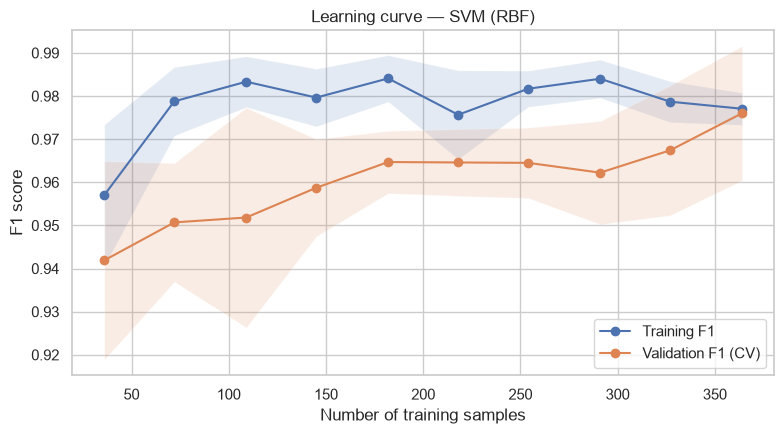

Final gap (train − validation F1): 0.0010


In [16]:
sizes, tr_scores, val_scores = learning_curve(final_model, X_train, y_train, cv=cv, scoring="f1",
                                              train_sizes=np.linspace(0.1, 1.0, 10), n_jobs=-1)
fig, ax = plt.subplots(figsize=(8, 4.5))
for scores, label in [(tr_scores, "Training F1"), (val_scores, "Validation F1 (CV)")]:
    m, s = scores.mean(axis=1), scores.std(axis=1)
    ax.plot(sizes, m, "o-", label=label); ax.fill_between(sizes, m - s, m + s, alpha=0.15)
ax.set_xlabel("Number of training samples"); ax.set_ylabel("F1 score")
ax.set_title(f"Learning curve — {FINAL_NAME}"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(FIG_DIR / "02_learning_curve.png", dpi=150); plt.show()
print(f"Final gap (train − validation F1): {tr_scores.mean(axis=1)[-1] - val_scores.mean(axis=1)[-1]:.4f}")

**Reading the curve:** both curves end high and very close together. The small gap means **no overfitting**, and
the high level means **no underfitting**. Validation F1 is still rising slightly at the right edge, so more data
would help a little, but the model is already near its ceiling for this dataset.

## 8. Save the final model and make a prediction for a new patient

In [17]:
joblib.dump({"model": final_model, "threshold": best_threshold, "features": FEATURES, "name": FINAL_NAME},
            MODEL_DIR / "final_model.joblib")
print("Saved → models/final_model.joblib")

bundle = joblib.load(MODEL_DIR / "final_model.joblib")
patient = X_test.iloc[[0]]
p = bundle["model"].predict_proba(patient)[0, 1]
verdict = "Malignant" if p >= bundle["threshold"] else "Benign"
print(f"Patient #0 → P(malignant) = {p:.3f} → predicted: {verdict} | actual: "
      f"{'Malignant' if y_test.iloc[0] == 1 else 'Benign'}")

Saved → models/final_model.joblib
Patient #0 → P(malignant) = 0.000 → predicted: Benign | actual: Benign


## 9. Summary of Program 1

In [18]:
final_row = thr_compare.iloc[1]
print(f"Final model          : {FINAL_NAME}")
print(f"Best hyperparameters : {tuning.loc[FINAL_NAME, 'best params']}")
print(f"CV F1 (train, tuned) : {tuning.loc[FINAL_NAME, 'tuned CV F1']:.4f}")
print(f"Decision threshold   : {best_threshold:.2f}")
print("Test set performance :")
for k in ["accuracy", "precision", "recall (sensitivity)", "specificity", "f1", "roc_auc"]:
    print(f"   {k:<22}{final_row[k]:.4f}")
print(f"   missed cancers (FN) {int(final_row['false negatives'])} of {int(y_test.sum())}")

summary = final_row.to_frame().T
summary.index = [f"{FINAL_NAME} @ threshold {best_threshold:.2f}"]
summary.to_csv(RES_DIR / "supervised_final_summary.csv")

Final model          : SVM (RBF)
Best hyperparameters : {'C': 3, 'class_weight': 'balanced', 'gamma': 0.01}
CV F1 (train, tuned) : 0.9760
Decision threshold   : 0.34
Test set performance :
   accuracy              0.9825
   precision             0.9762
   recall (sensitivity)  0.9762
   specificity           0.9861
   f1                    0.9762
   roc_auc               0.9974
   missed cancers (FN) 1 of 42


### Conclusions of Program 1
1. **Scaled linear and kernel models do best.** After standardisation the classes are almost linearly separable,
   so Logistic Regression and the RBF-SVM beat the tree ensembles. A single Decision Tree overfits (lowest score, highest variance).
2. **Tuning helped most for the SVM** (smaller `gamma` gives a smoother boundary; `class_weight='balanced'` pays more attention to the minority malignant class).
   It had the best cross-validated F1, so it was chosen as the final model **before** the test set was used.
3. **On 114 unseen patients** the final model reaches about **98% accuracy and ROC-AUC ≈ 0.997**.
4. **Threshold tuning** (chosen on training folds only) trades one false alarm for one fewer missed cancer,
   which is the right trade-off in a screening setting.
5. **The model's decisions make medical sense:** the "worst" features (the largest, most abnormal nuclei) dominate.
   *Worst texture, worst radius, worst concave points and worst concavity* drive the SVM, and the Random Forest relies on
   *worst perimeter / area / concave points*. These are the signs of enlarged, irregular nuclei that pathologists look for.
6. **Limitations:** a small single-hospital dataset (569 patients), so results should be validated on external data
   before any clinical use. This is a decision-support tool, not a replacement for a doctor.